# КТ5 · От ошибки колёс к ошибке карты
Продолжение учебного FusionLab после F9. Станции F10–F12 выполняются на CPU. В ноутбук вложены исходные модули стенда из мастерской, обученная в F9 LSTM и контрольный бустинг. Все таблицы F10–F12 пересчитываются. Источник весов — архив `FusionLab_F9_models.zip` из предыдущего занятия. В конце проверяю экспорт на новом маршруте 6000.

**Прогноз до опыта.** В штатном режиме продольную ошибку колёс удастся уменьшить. После смены знака та же поправка усилит дрейф. Ожидаю, что калибровка приблизит коэффициент к нулю и вернёт исходную оценку с весом 0,15 м. Эффект проверяется попарно на одинаковых маршрутах.

Для F10 я выбрал LSTM до тестов F12. На валидации F9 её RMSE составила 0,0920 м, у CNN — 0,0972 м, у MLP — 0,1136 м. Бустинг с RMSE 0,0836 м остаётся отдельной базовой моделью.

In [1]:
# В Colab согласуем формат сохранённого sklearn-предиктора с версией F9.
import importlib.metadata, subprocess, sys
if importlib.metadata.version('scikit-learn') != '1.7.2':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.7.2'])
%matplotlib inline

In [2]:
# @title Подготовка среды
import os, sys, importlib.util, importlib, json, shutil, time
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
# В Colab используется TensorFlow; локально возможен backend PyTorch для Keras 3.
backend = 'tensorflow' if importlib.util.find_spec('tensorflow') else 'torch'
if not importlib.util.find_spec(backend):
    raise RuntimeError('Нужен TensorFlow (Colab) или PyTorch для локального запуска Keras 3')
os.environ['KERAS_BACKEND'] = backend
from pathlib import Path
from dataclasses import replace
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
threadpool_limits(1)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':.22,
                     'axes.spines.top':False, 'axes.spines.right':False})
BLUE, TEAL, GOLD, GRAY, RED = '#365e9b','#16877c','#ba8435','#718096','#b54b4b'
Path('fusionlab').mkdir(exist_ok=True)
Path('fusionlab/__init__.py').write_text('"""FusionLab teaching library."""\n', encoding='utf-8')
print('Среда обучения:', backend, '| Python:', sys.version.split()[0])

Среда обучения: tensorflow | Python: 3.12.16


In [3]:
%%writefile fusionlab/slam_core.py
"""Small, transparent batch 2-D factor-graph SLAM core for a Jupyter workshop.

No simulation engine, ROS, or learned estimator.  The measurement generator
below is synthetic; ground truth is used ONLY for verification/benchmarks.
Conventions: world poses (x [m], y [m], yaw [rad]); body x points forwards,
body y to the left; landmark bearings measured counter-clockwise from body x.
The first robot pose is fixed to (0, 0, 0) to remove planar gauge freedom.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import List
import numpy as np


def wrap(a):
    return (np.asarray(a) + np.pi) % (2.0 * np.pi) - np.pi


@dataclass
class Factor:
    kind: str             # wheel, visual, loop, gyro, landmark, bias_prior
    i: int                # pose index (or 0 for bias prior)
    j: int                # pose index or landmark index
    z: np.ndarray         # observed quantities; no ground truth here
    sigma: np.ndarray     # per-component standard deviations in native units
    dt: float = 1.0
    tag: str = ""         # diagnostic only: never read by the solver


@dataclass
class Dataset:
    """Sensor factors may be used without ground truth in a future data adapter."""
    factors: List[Factor]
    nposes: int
    nlandmarks: int
    seed: int = -1
    true_gyro_bias: float | None = None
    truth_poses: np.ndarray | None = None
    truth_landmarks: np.ndarray | None = None


def relative_pose(pi, pj):
    """Pose of j in frame i, as [body-frame dx, dy, wrapped dyaw]."""
    dx, dy = pj[:2] - pi[:2]
    c, s = np.cos(pi[2]), np.sin(pi[2])
    return np.array([c*dx + s*dy, -s*dx + c*dy, wrap(pj[2]-pi[2])])


def integrate_relative(p, z):
    c, s = np.cos(p[2]), np.sin(p[2])
    return np.array([p[0] + c*z[0] - s*z[1],
                     p[1] + s*z[0] + c*z[1],
                     wrap(p[2] + z[2])])


def range_bearing(pose, landmark):
    d = landmark - pose[:2]
    r = np.linalg.norm(d)
    if r < 1.e-10:
        raise ValueError("Landmark too close to robot for bearing")
    return np.array([r, wrap(np.arctan2(d[1], d[0]) - pose[2])])


def make_dataset(seed=23, nposes=18, false_loop=True, outliers=True):
    """Generate independent sensor noises; not a physics-accurate simulator.

    Circular unicycle-like route, returning to the start. The generator uses
    exactly known landmark IDs; data association is out of the core scope.
    """
    if nposes < 8:
        raise ValueError("Need at least 8 poses")
    rng = np.random.default_rng(seed)
    ts = np.linspace(0., 2.*np.pi, nposes)
    radius = 2.2
    poses = np.stack([radius*np.sin(ts), radius*(1.-np.cos(ts)), wrap(ts)], axis=1)
    landmarks = np.array([[-1.2, 1.0], [1.1, -0.6], [3.7, 1.2],
                          [3.2, 3.9], [1.1, 5.1], [-1.3, 3.8]], float)
    factors = []
    gyro_bias = 0.027  # radians/second, constant; here dt=1 second

    for i in range(nposes-1):
        z = relative_pose(poses[i], poses[i+1])
        wheel_sig = np.array([.075, .20, .060])
        wheel = z.copy() + rng.normal(0, wheel_sig)
        wheel[1] = rng.normal(0, wheel_sig[1])  # nonholonomic dy~0, soft assumption
        wheel[2] = wrap(wheel[2])
        factors.append(Factor("wheel", i, i+1, wheel, wheel_sig))
        if rng.random() >= .25:
            sig = np.array([.040, .040, .027])
            visual = z.copy() + rng.normal(0, sig)
            visual[2] = wrap(visual[2])
            factors.append(Factor("visual", i, i+1, visual, sig))
        yaw = wrap(z[2] + gyro_bias + rng.normal(0, .025))
        factors.append(Factor("gyro", i, i+1, np.array([yaw]),
                              np.array([.025]), dt=1.0))

    zloop = relative_pose(poses[0], poses[-1])
    factors.append(Factor("loop", 0, nposes-1,
                          zloop + rng.normal(0, [.07, .07, .040]),
                          np.array([.07, .07, .040]), tag="verified_loop"))
    # The false image match below is an intentionally misassociated loop closure.
    # Robust estimation can help; real pipelines must verify loop candidates.
    if false_loop:
        factors.append(Factor("loop", 0, nposes//2,
                              rng.normal(0, [.05, .05, .03]),
                              np.array([.12, .12, .075]), tag="false_loop"))

    for i, pose in enumerate(poses):
        for j, landmark in enumerate(landmarks):
            z = range_bearing(pose, landmark)
            if z[0] > 4.3 or rng.random() < .25:
                continue
            sig = np.array([.10, .045])
            obs = z + rng.normal(0, sig)
            bad = outliers and rng.random() < .09
            if bad:
                obs += np.array([rng.choice([-1., 1.])*rng.uniform(.8,1.8),
                                 rng.choice([-1., 1.])*rng.uniform(.15,.55)])
            obs[0] = max(.05, obs[0])
            obs[1] = wrap(obs[1])
            factors.append(Factor("landmark", i, j, obs, sig,
                                  tag="injected_outlier" if bad else ""))
    factors.append(Factor("bias_prior", 0, 0, np.array([0.]), np.array([.12])))
    return Dataset(factors=factors, nposes=len(poses),
                   nlandmarks=len(landmarks), seed=int(seed),
                   true_gyro_bias=gyro_bias,
                   truth_poses=poses, truth_landmarks=landmarks)


def wheel_dead_reckoning(data):
    out = np.zeros((data.nposes,3))
    for f in data.factors:
        if f.kind == "wheel":
            out[f.j] = integrate_relative(out[f.i], f.z)
    return out


def initial_state(data):
    """Initialize poses using wheel odometry and landmarks using observations.

    Do not access hidden truth fields except for array lengths.
    """
    poses = wheel_dead_reckoning(data)
    landmark_candidates = [[] for _ in range(data.nlandmarks)]
    for f in data.factors:
        if f.kind == "landmark":
            p = poses[f.i]
            direction = p[2] + f.z[1]
            point = p[:2] + f.z[0]*np.array([np.cos(direction),np.sin(direction)])
            landmark_candidates[f.j].append(point)
    landmarks = []
    for j, items in enumerate(landmark_candidates):
        if not items:
            raise ValueError(f"Landmark {j} was not observed")
        landmarks.append(np.median(np.asarray(items), axis=0))
    return pack_state(poses, np.array(landmarks), bias=0.)


def pack_state(poses, landmarks, bias=0.0):
    poses = np.asarray(poses, float)
    landmarks = np.asarray(landmarks, float)
    if poses.shape[1] != 3 or landmarks.shape[1] != 2:
        raise ValueError("Wrong pose/landmark dimensions")
    if not np.allclose(poses[0], 0., atol=1e-12):
        raise ValueError("First pose must be fixed at the origin")
    return np.r_[poses[1:].ravel(), landmarks.ravel(), float(bias)]


def unpack_state(x, nposes, nlandmarks):
    x = np.asarray(x, float)
    count = 3*(nposes-1)
    end = count + 2*nlandmarks
    if x.size != end+1:
        raise ValueError("Wrong state vector size")
    poses = np.vstack((np.zeros(3), x[:count].reshape(-1,3)))
    landmarks = x[count:end].reshape(-1,2)
    return poses, landmarks, float(x[-1])


def _jac_relative(pi, pj):
    dx,dy=pj[:2]-pi[:2]
    c,s=np.cos(pi[2]),np.sin(pi[2])
    u,v=c*dx+s*dy,-s*dx+c*dy
    ji=np.array([[-c,-s, v],[s,-c,-u],[0.,0.,-1.]])
    jj=np.array([[c,s,0.],[-s,c,0.],[0.,0.,1.]])
    return ji,jj


def _jac_landmark(p, lm):
    dx, dy = lm - p[:2]
    q = dx*dx+dy*dy
    if q < 1e-12:
        raise ValueError("Landmark measurement singular at zero range")
    r = np.sqrt(q)
    jp = np.array([[-dx/r,-dy/r,0.],[dy/q,-dx/q,-1.]])
    jl = np.array([[dx/r,dy/r],[-dy/q,dx/q]])
    return jp, jl


def _slice_pose(i):
    return None if i == 0 else slice(3*(i-1),3*i)


def _slice_landmark(j, nposes):
    k=3*(nposes-1)+2*j
    return slice(k,k+2)


def residual_jacobian(x, data, use_visual=True, use_landmarks=True,
                      use_gyro=True, use_loop=True, jac=True):
    """Whitened residual, analytic Jacobian, and per-factor row blocks.

    Tightly related components of an observation share one Huber block.
    """
    poses,lms,bias=unpack_state(x,data.nposes,data.nlandmarks)
    nd=x.size
    residuals=[]; matrices=[]; blocks=[]; active=[]
    cursor=0
    for f in data.factors:
        if f.kind == "visual" and not use_visual:
            continue
        if f.kind == "loop" and (not use_visual or not use_loop):
            continue
        if f.kind == "landmark" and not use_landmarks:
            continue
        if f.kind == "gyro" and not use_gyro:
            continue
        if f.kind == "bias_prior" and not use_gyro:
            continue
        jrow = np.zeros((len(f.z),nd)) if jac else None
        if f.kind in ("wheel", "visual", "loop"):
            pred=relative_pose(poses[f.i],poses[f.j])
            r=pred-f.z
            r[2]=wrap(r[2])
            if jac:
                ji,jj=_jac_relative(poses[f.i],poses[f.j])
                if f.i>0: jrow[:,_slice_pose(f.i)]=ji
                if f.j>0: jrow[:,_slice_pose(f.j)]=jj
        elif f.kind == "landmark":
            pred=range_bearing(poses[f.i],lms[f.j])
            r=pred-f.z
            r[1]=wrap(r[1])
            if jac:
                ji,jl=_jac_landmark(poses[f.i],lms[f.j])
                if f.i>0: jrow[:,_slice_pose(f.i)]=ji
                jrow[:,_slice_landmark(f.j,data.nposes)]=jl
        elif f.kind == "gyro":
            r=np.array([wrap(poses[f.j,2]-poses[f.i,2]+bias*f.dt-f.z[0])])
            if jac:
                if f.i>0: jrow[0,_slice_pose(f.i).start+2]=-1.
                if f.j>0: jrow[0,_slice_pose(f.j).start+2]=1.
                jrow[0,-1]=f.dt
        elif f.kind == "bias_prior":
            r=np.array([bias-f.z[0]])
            if jac: jrow[0,-1]=1.
        else:
            raise ValueError("Unknown factor kind: "+f.kind)
        residuals.append(r/f.sigma)
        if jac: matrices.append(jrow/f.sigma[:,None])
        blocks.append(slice(cursor,cursor+len(r)))
        active.append(f)
        cursor+=len(r)
    rval=np.concatenate(residuals)
    return rval,(np.vstack(matrices) if jac else None),blocks,active


def objective(resid, blocks, factors, robust=True, threshold=2.5):
    val=0.
    for block,f in zip(blocks,factors):
        norm=np.linalg.norm(resid[block])
        if robust and f.kind in ("visual", "loop", "landmark") and norm>threshold:
            val+=threshold*(norm-.5*threshold)
        else:
            val+=.5*norm*norm
    return float(val)


def irls_weights(r,blocks,factors,robust=True,threshold=2.5):
    w=np.ones_like(r)
    if robust:
        for sl,f in zip(blocks,factors):
            if f.kind in ("visual", "loop", "landmark"):
                n=np.linalg.norm(r[sl])
                if n>threshold:
                    w[sl]=threshold/n
    return w


def solve(data, x0=None, robust=True, use_visual=True,
          use_landmarks=True, use_gyro=True, use_loop=True,
          max_iter=40, lam0=1.e-3, gtol=5.e-6):
    """Adaptive damped GN + block-Huber IRLS. This is a local optimizer.

    Initial pose anchored by parameterization. Returns status, objective history,
    state and estimated trajectory/map; never accesses ground truth positions.
    """
    x=initial_state(data) if x0 is None else np.asarray(x0,float).copy()
    args=dict(use_visual=use_visual,use_landmarks=use_landmarks,
              use_gyro=use_gyro,use_loop=use_loop)
    lam=float(lam0); hist=[]; accepted=0; status="max_iter"
    for iteration in range(max_iter):
        r,j,blocks,factors=residual_jacobian(x,data,**args)
        val=objective(r,blocks,factors,robust)
        hist.append(val)
        w=np.sqrt(irls_weights(r,blocks,factors,robust))
        jw=j*w[:,None]; rw=r*w
        h=jw.T@jw
        grad=jw.T@rw
        if np.linalg.norm(grad,np.inf)<gtol:
            status="gradient_small";break
        diag=np.maximum(h.diagonal(),1.)
        succeeded=False
        for trial in range(15):
            step=np.linalg.solve(h+lam*np.diag(diag),-grad)
            if not np.all(np.isfinite(step)):
                raise FloatingPointError("Nonfinite optimization step")
            if np.linalg.norm(step)<1.e-9*(1.+np.linalg.norm(x)):
                status="step_small";succeeded=True;break
            cand=x+step
            # Bearing is undefined if a tested landmark coincides with a pose.
            # Reject such a trial rather than allowing a singular Jacobian on
            # the next iteration; no invented direction is inserted.
            if use_landmarks:
                cp, cl, _ = unpack_state(cand, data.nposes, data.nlandmarks)
                if any(f.kind == "landmark" and
                       np.sum((cp[f.i,:2]-cl[f.j])**2) < 1.e-10
                       for f in data.factors):
                    lam=min(lam*7.,1.e12)
                    continue
            # All pose yaw angles live in S1; use local Euclidean coordinates.
            for idx in range(2,3*(data.nposes-1),3):
                cand[idx]=wrap(cand[idx])
            rr,_,bb,ff=residual_jacobian(cand,data,jac=False,**args)
            newval=objective(rr,bb,ff,robust)
            if np.isfinite(newval) and newval<val:
                x=cand; lam=max(lam/3.,1.e-9)
                accepted+=1; succeeded=True;break
            lam=min(lam*7.,1.e12)
        if status=="step_small":break
        if not succeeded:
            status="stalled";break
    r,j,blocks,factors=residual_jacobian(x,data,**args)
    hist.append(objective(r,blocks,factors,robust))
    poses,lms,bias=unpack_state(x,data.nposes,data.nlandmarks)
    return dict(x=x,poses=poses,landmarks=lms,bias=bias,
                objective=hist[-1],history=np.array(hist),
                status=status,steps=accepted,lambda_final=lam,
                active_factors=len(factors))


def metrics(estimate, data, include_map=True):
    if data.truth_poses is None or data.truth_landmarks is None:
        raise ValueError("Ground truth required for benchmarks; never for solving")
    p=estimate["poses"]; t=data.truth_poses
    if len(p)!=len(t): raise ValueError("Different trajectory lengths")
    e=np.linalg.norm(p[:,:2]-t[:,:2],axis=1)
    rpe=np.linalg.norm(np.diff(p[:,:2],axis=0)-np.diff(t[:,:2],axis=0),axis=1)
    yaw=wrap(p[:,2]-t[:,2])
    ans=dict(ate_rmse_m=float(np.sqrt(np.mean(e**2))),
             rpe_xy_rmse_m=float(np.sqrt(np.mean(rpe**2))),
             yaw_rmse_rad=float(np.sqrt(np.mean(yaw**2))),
             gyro_bias_error_rad_step=float(estimate["bias"]-data.true_gyro_bias))
    if include_map:
        le=np.linalg.norm(estimate["landmarks"]-data.truth_landmarks,axis=1)
        ans["landmark_rmse_m"]=float(np.sqrt(np.mean(le**2)))
    return ans


def visual_coverage(data):
    return sum(f.kind=="visual" for f in data.factors)/float(data.nposes-1)


def neumann_demo(A,b,num_iterations=25):
    """Fixed point for SPD normal equations; provable contraction in l2."""
    H=A.T@A
    rhs=A.T@b
    eigen=np.linalg.eigvalsh(H)
    if eigen[0]<=0: raise ValueError("Fix the gauge first: SPD required")
    step=1.0/eigen[-1]
    alpha=max(abs(1.-step*eigen[0]),abs(1.-step*eigen[-1]))
    x=np.zeros(H.shape[0]); it=[x.copy()]
    for _ in range(num_iterations):
        x=x-step*(H@x-rhs)
        it.append(x.copy())
    return np.asarray(it),alpha,np.linalg.solve(H,rhs)


def previous_vo_camera_to_body_delta(T_new_old_camera,T_body_camera):
    """Bridge from old notebook estimate_pair output T_Cj_Ci.

    Both homogeneous transforms must be in meters. A fixed, calibrated
    T_body_camera is essential; never assume optical and body axes coincide.
    Returns [dx,dy,dyaw] of body j w.r.t. body i in frame Bi.
    """
    camera=np.asarray(T_new_old_camera,float)
    bc=np.asarray(T_body_camera,float)
    if camera.shape!=(4,4) or bc.shape!=(4,4):
        raise ValueError("Expected two 4x4 homogeneous transforms")
    b_i_b_j=bc@np.linalg.inv(camera)@np.linalg.inv(bc)
    angle=np.arctan2(b_i_b_j[1,0],b_i_b_j[0,0])
    return np.array([b_i_b_j[0,3],b_i_b_j[1,3],wrap(angle)])

Overwriting fusionlab/slam_core.py


In [4]:
%%writefile fusionlab/synthetic.py
"""Synthetic teaching generator adapted verbatim from the final-sprint pilot.
The input channels are dimensionless synthetic diagnostic proxies, not actual sensors.
Ground truth is returned separately for training labels and benchmarking.
"""
import numpy as np
from . import slam_core as sc

W=8; T=24

def generate(seed,regime='nominal'):
    rng=np.random.default_rng(seed)
    load=np.empty(T); vib=np.empty(T); load[0]=rng.uniform(-1,1); vib[0]=rng.uniform(-1,1)
    for k in range(1,T):
        load[k]=np.clip(.65*load[k-1]+rng.normal(0,.55),-1.5,1.5)
        vib[k]=np.clip(.72*vib[k-1]+rng.normal(0,.50),-1.5,1.5)
    features=np.column_stack([load,vib])+rng.normal(0,.12,(T,2))
    # Assumed persistent nonlinear slip (m per interval); diagnostic features are synthetic.
    b=np.zeros(T); prev=0.
    for k in range(T):
        target=.38*np.tanh(2.2*(load[k]+.45*vib[k]-.15))+.15*np.tanh(2.5*load[k]*vib[k])
        prev=.45*prev+.55*target; b[k]=prev
    if regime=='null': b[:]=0.
    if regime=='shift': b=-b
    poses=np.zeros((T+1,3)); factors=[]; labels=[]
    for k in range(T):
        dyaw=.20+.12*np.sin(k*.43+seed*.1)+rng.normal(0,.025)
        dx=.48+.09*np.cos(k*.65+seed*.2)+rng.normal(0,.025)
        d=np.array([dx,.02*np.sin(k*.4),dyaw]); poses[k+1]=sc.integrate_relative(poses[k],d)
        sig=np.array([.065,.08,.045]); w=d+rng.normal(0,sig); w[0]+=b[k]; w[2]=sc.wrap(w[2]); labels.append(w[0]-d[0])
        factors.append(sc.Factor('wheel',k,k+1,w,sig.copy()))
        if rng.random()<.45:
            s=np.array([.065,.065,.038]); z=d+rng.normal(0,s); z[2]=sc.wrap(z[2]); factors.append(sc.Factor('visual',k,k+1,z,s))
        factors.append(sc.Factor('gyro',k,k+1,np.array([sc.wrap(dyaw+.025+rng.normal(0,.025))]),np.array([.025])))
    idx=np.linspace(2,T-2,6,dtype=int); landmarks=poses[idx,:2]+rng.normal(0,1.,(6,2))
    for j,pt in enumerate(landmarks):
        closest=np.argsort(np.linalg.norm(poses[:,:2]-pt,axis=1))[:5]
        for k in closest:
            z=sc.range_bearing(poses[k],pt)+rng.normal(0,[.12,.055]); z[0]=max(.05,z[0]); z[1]=sc.wrap(z[1]); factors.append(sc.Factor('landmark',int(k),j,z,np.array([.12,.055])))
    factors.append(sc.Factor('bias_prior',0,0,np.array([0.]),np.array([.12])))
    data=sc.Dataset(factors,T+1,6,seed,.025,poses,landmarks)
    pad=np.vstack([np.zeros((W-1,2)),features]); windows=np.stack([pad[k:k+W] for k in range(T)])
    return windows,np.asarray(labels),data

def arrays(seeds):
    pairs=[generate(s) for s in seeds]; return np.concatenate([p[0] for p in pairs]),np.concatenate([p[1] for p in pairs])

Overwriting fusionlab/synthetic.py


In [5]:
%%writefile fusionlab/geometry2d.py
"""SE(2) helpers: p=[x (m), y (m), theta (rad)]."""
import numpy as np
from .slam_core import wrap, relative_pose, integrate_relative, range_bearing


def rotation(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])


def pose_matrix(p):
    T = np.eye(3)
    T[:2, :2] = rotation(p[2])
    T[:2, 2] = p[:2]
    return T


def inverse(T):
    R, t = T[:2, :2], T[:2, 2]
    ans = np.eye(3)
    ans[:2, :2] = R.T
    ans[:2, 2] = -R.T @ t
    return ans


def fk2r(q, lengths=(1., 1.)):
    """Position (m) of a planar two-link arm tip, joint angles in radians."""
    T1 = pose_matrix([0., 0., q[0]]) @ pose_matrix([lengths[0], 0., 0.])
    T2 = pose_matrix([0., 0., q[1]]) @ pose_matrix([lengths[1], 0., 0.])
    return (T1 @ T2)[:2, 2]

Overwriting fusionlab/geometry2d.py


In [6]:
%%writefile fusionlab/linear_solver.py
"""Weighted linear least squares, anchored 1-D graph, fixed-point iteration."""
import numpy as np


def normal_system(A, z, sigma):
    A, z, sigma = map(lambda v: np.asarray(v, float), (A, z, sigma))
    if A.ndim != 2 or z.shape != (A.shape[0],) or sigma.shape != z.shape:
        raise ValueError('incompatible shapes')
    if not (np.isfinite(A).all() and np.isfinite(z).all() and
            np.isfinite(sigma).all() and (sigma > 0).all()):
        raise ValueError('finite inputs and positive sigma required')
    B, d = A / sigma[:, None], z / sigma
    if np.linalg.matrix_rank(B) != A.shape[1]:
        raise ValueError('unobservable direction: fix gauge or add information')
    return B.T @ B, B.T @ d, B, d


def fixed_point(H, b, x0=None, alpha=None, tol=1e-8, max_iter=5000):
    H, b = np.asarray(H,float), np.asarray(b,float)
    if H.shape != (b.size,b.size) or not np.allclose(H,H.T):
        raise ValueError('symmetric square H required')
    eig = np.linalg.eigvalsh(H)
    mu, L = eig[0], eig[-1]
    if not np.isfinite(eig).all() or mu <= 0:
        raise ValueError('H must be positive definite')
    alpha = 2/(mu+L) if alpha is None else float(alpha)
    if not (0 < alpha < 2/L):
        raise ValueError('alpha outside proven contraction interval')
    c = max(abs(1-alpha*mu), abs(1-alpha*L))
    x = np.zeros_like(b) if x0 is None else np.asarray(x0,float).copy()
    history = [x.copy()]
    for _ in range(max_iter):
        if np.linalg.norm(H@x-b)/mu <= tol:
            break
        x -= alpha*(H@x-b)
        history.append(x.copy())
    bound = np.linalg.norm(H@x-b)/mu
    return dict(x=x, history=np.asarray(history), c=c, mu=mu, L=L,
                alpha=alpha, error_bound=bound,
                status='tolerance' if bound <= tol else 'max_iter')

Overwriting fusionlab/linear_solver.py


In [7]:
%%writefile fusionlab/learned_sensor.py
"""Learn the forward wheel residual [m] from a causal window of diagnostics."""
import numpy as np
import keras
from keras import layers
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor


def build_classical(X, y):
    flat = X.reshape(len(X), -1)
    models = {
        'ridge': make_pipeline(StandardScaler(), Ridge(alpha=3.)),
        'poly': make_pipeline(PolynomialFeatures(2, include_bias=False),
                              StandardScaler(), Ridge(alpha=15.)),
        'boost': HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=15,
                    l2_regularization=1., random_state=9),
    }
    for m in models.values():
        m.fit(flat, y)
    return models


def build_network(name, window=8, width=24, lr=.003):
    inp = keras.Input((window, 2))
    if name == 'mlp':
        x = layers.Flatten()(inp)
        x = layers.Dense(width, activation='tanh')(x)
    elif name == 'cnn':
        x = layers.Conv1D(16, 3, padding='causal', activation='tanh')(inp)
        x = layers.Flatten()(x)
        x = layers.Dense(12, activation='tanh')(x)
    elif name == 'lstm':
        x = layers.LSTM(16)(inp)
    else:
        raise ValueError('unknown architecture')
    model = keras.Model(inp, layers.Dense(1)(x), name=name)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse')
    return model


def fit_network(name, X, y, Xv, yv, epochs=15, width=24, lr=.003, seed=42):
    keras.utils.set_random_seed(seed)
    model = build_network(name, X.shape[1], width, lr)
    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                              restore_best_weights=True)
    h = model.fit(X,y,validation_data=(Xv,yv),epochs=epochs,
                  batch_size=128,verbose=0,callbacks=[callback])
    return model, h.history


def predict_bias(model, X, constant=0.):
    """X.shape=(n_windows, window, 2), output=(n_windows,) in metres."""
    X = np.asarray(X,float)
    if X.ndim != 3 or X.shape[-1] != 2 or not np.isfinite(X).all():
        raise ValueError('invalid causal windows')
    if model is None:
        p = np.full(len(X), constant)
    elif isinstance(model, keras.Model):
        p = model.predict(X, verbose=0).ravel()
    else:
        p = model.predict(X.reshape(len(X), -1)).ravel()
    if not np.isfinite(p).all():
        raise ValueError('nonfinite predictor')
    return np.clip(p, -.55, .55)

Overwriting fusionlab/learned_sensor.py


In [8]:
# Веса F9 сохранены внутри ноутбука для автономного запуска.
import base64, io, zipfile, joblib, keras
from fusionlab import learned_sensor as ls
payload = (
    '...'
    'AAAAXrIBAAAA'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as archive:
    manifest=json.loads(archive.read('manifest.json'))
    val_all=pd.read_csv(io.BytesIO(archive.read('baseline_metrics.csv')),index_col=0)
    Path('f9_lstm.keras').write_bytes(archive.read('lstm.keras'))
    predictors={'lstm':keras.models.load_model('f9_lstm.keras',compile=False),
                'boost':joblib.load(io.BytesIO(archive.read('boost.joblib')))}
def predict(name,X):
    return ls.predict_bias(predictors[name],X)
assert manifest['base_for_F10_F12']=='lstm'
print('Модель из F9:', manifest['base_for_F10_F12'], '| окно', manifest['input_shape'])


Модель из F9: lstm | окно [8, 2]


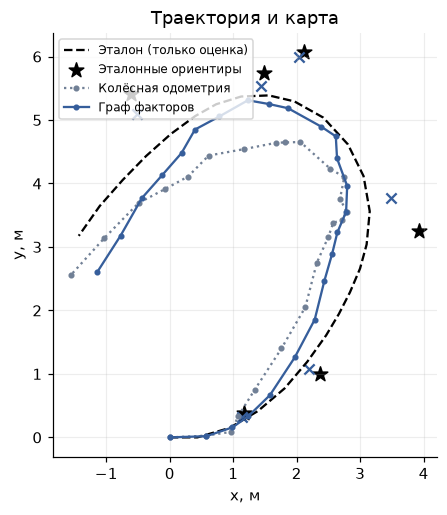

RMSE по колёсам: 0.6189 м
RMSE графа: 0.3895 м
Статус решателя: gradient_small


In [9]:
from fusionlab import slam_core as sc, synthetic as sy
W, T = sy.W, sy.T

def observed(data):
    # Удаляем эталонные позы, карту и истинное смещение гироскопа.
    return replace(data, truth_poses=None, truth_landmarks=None, true_gyro_bias=None)

def plot_estimate(ref, raw_poses, sols, title='Траектория и карта'):
    fig, ax=plt.subplots(figsize=(8,5))
    p=ref.truth_poses; m=ref.truth_landmarks
    ax.plot(p[:,0],p[:,1],'k--',lw=1.5,label='Эталон (только оценка)')
    ax.scatter(*m.T,marker='*',s=100,c='k',label='Эталонные ориентиры')
    if raw_poses is not None:
        ax.plot(*raw_poses[:,:2].T,':o',ms=3,color=GRAY,label='Колёсная одометрия')
    for (name,sol),color in zip(sols.items(),[BLUE,TEAL,GOLD,RED]):
        ax.plot(*sol['poses'][:,:2].T,'o-',ms=3,color=color,label=name)
        ax.scatter(*sol['landmarks'].T,marker='x',s=45,color=color)
    ax.set(title=title,xlabel='x, м',ylabel='y, м',aspect='equal'); ax.legend(loc='best',fontsize=8)
    plt.show()

X_demo, y_demo, ref_demo = sy.generate(23)
raw_demo = observed(ref_demo)
wheel_path = sc.wheel_dead_reckoning(raw_demo)
sol_demo = sc.solve(raw_demo,max_iter=25)
plot_estimate(ref_demo,wheel_path,{'Граф факторов':sol_demo})
wheel_ate=np.sqrt(np.mean(np.sum((wheel_path[:,:2]-ref_demo.truth_poses[:,:2])**2,axis=1)))
print('RMSE по колёсам:',round(wheel_ate,4),'м')
print('RMSE графа:',round(sc.metrics(sol_demo,ref_demo)['ate_rmse_m'],4),'м')
print('Статус решателя:',sol_demo['status'])

In [10]:
from fusionlab.linear_solver import normal_system, fixed_point
A=np.array([[1,0,0],[-1,1,0],[0,-1,1],[0,0,1.]],float)
z=np.array([1.,1.1,1.,2.8]); sigma=np.full(4,.1)
H,b,B,d=normal_system(A,z,sigma)
answer=np.linalg.solve(H,b)
independent=np.linalg.lstsq(B,d,rcond=None)[0]
np.testing.assert_allclose(answer,independent,atol=1e-12)
print('A =\n',A,'\nH =\n',H,'\nb =',b)
print('Решение, м:',answer,'\nНормированные невязки:',B@answer-d)
print('Проверка Bᵀ(Bx−d):',B.T@(B@answer-d))

A =
 [[ 1.  0.  0.]
 [-1.  1.  0.]
 [ 0. -1.  1.]
 [ 0.  0.  1.]] 
H =
 [[ 200. -100.    0.]
 [-100.  200. -100.]
 [   0. -100.  200.]] 
b = [-10.  10. 380.]
Решение, м: [0.925 1.95  2.875] 
Нормированные невязки: [-0.75 -0.75 -0.75  0.75]
Проверка Bᵀ(Bx−d): [0. 0. 0.]


In [11]:
TRAIN=manifest['training_route_seeds']; VAL=manifest['validation_route_seeds']
CAL=list(range(4000,4008)); TEST=list(range(5000,5005))
groups=list(map(set,(TRAIN,VAL,CAL,TEST)))
assert all(a.isdisjoint(b) for i,a in enumerate(groups) for b in groups[i+1:])

## F10. От ошибки колёс к ошибке карты

Подключаю обученную на F9 LSTM к колёсному фактору. Сравниваю отдельно ошибку самого датчика и ошибку восстановленной траектории.

### Что даёт информация о режиме

У датчика в режиме A ошибка равна 0,1 или 0,3 м, в режиме B — −0,1 или −0,3 м. Все четыре случая равновероятны. Общая средняя ошибка равна нулю. Зная режим, можно вычитать 0,2 м в A и прибавлять 0,2 м в B. Средний квадрат остатка меняется с 0,05 до 0,01 м².

In [12]:
# Ровно четыре равновероятных исхода; никаких обучаемых параметров.
Y=np.array([.1,.3,-.1,-.3]); Xmode=np.array(['A','A','B','B'])
m=np.array([.2,.2,-.2,-.2]); h=np.full(4,Y.mean())
print('Без признака, MSE:',np.mean((Y-h)**2),'м²')
print('С признаком, MSE:',np.mean((Y-m)**2),'м²')
print('Остаток в каждом режиме:',[np.mean((Y-m)[Xmode==q]) for q in ['A','B']])
np.testing.assert_allclose(np.mean((Y-h)**2),np.mean((Y-m)**2)+np.mean((m-h)**2),atol=1e-14)

Без признака, MSE: 0.05 м²
С признаком, MSE: 0.009999999999999998 м²
Остаток в каждом режиме: [np.float64(-1.3877787807814457e-17), np.float64(1.3877787807814457e-17)]


Для ошибки колёс $Y$ и окна признаков $X$ лучшая по средней квадратичной ошибке поправка равна $m(X)=\mathbb E[Y\mid X]$. Если $Y$ и прогноз $h(X)$ имеют конечные вторые моменты, то
$$\mathbb E[(Y-h)^2]=\mathbb E[(Y-m)^2]+\mathbb E[(m-h)^2].$$
Смешанный член исчезает, поскольку среднее $Y-m$ при данном $X$ равно нулю. В граф я передаю продольное приращение $z_x-a p$, где $p$ — прогноз LSTM в метрах за интервал, $a$ — доверие от 0 до 1. Остальные компоненты измерения сохраняю.

### Адаптер продольной поправки
В этом решении один и тот же модуль калибрует доверие и заменяет измерение как в учебном наборе F9, так и в графе КТ3. Для межсенсорной пары проверяются начало и конец интервала.

In [13]:
%%writefile fusionlab/wheel_channel.py
"""One calibrated forward-wheel correction, usable with the lab graph or the F9 stand."""
from dataclasses import replace
import numpy as np


def scale_from_pairs(prediction, difference):
    p, d = np.asarray(prediction,float), np.asarray(difference,float)
    if p.ndim != 1 or d.shape != p.shape or not len(p) or not np.isfinite(np.r_[p,d]).all():
        return dict(a=0.,n_pairs=0,before=np.nan,after=np.nan,status='no_valid_calibration')
    norm2 = p @ p
    alpha = float(np.clip((p @ d) / norm2, 0., 1.)) if norm2 > 0 else 0.
    return dict(a=alpha,n_pairs=len(p),before=float(np.mean(d**2)),after=float(np.mean((d-alpha*p)**2)),
                status='calibrated' if norm2>0 else 'zero_prediction')


def observable(data):
    for key in ('truth_poses','truth_landmarks','true_gyro_bias'):
        if getattr(data,key,None) is not None:
            raise ValueError('remove reference fields before inference')


def differences(data, visual_kind):
    """Match both ends of a unit interval. Each sensor contributes at most one observation."""
    observable(data)
    by_sensor={'wheel':{},visual_kind:{}}
    for factor in data.factors:
        if factor.kind not in by_sensor:
            continue
        if factor.j != factor.i + 1:
            raise ValueError('wheel and visual factors must span one interval')
        key=(factor.i,factor.j)
        readings=by_sensor[factor.kind]
        if key in readings:
            raise ValueError('duplicate sensor observation on one interval')
        readings[key]=float(factor.z[0])
    wheel,visual=by_sensor['wheel'],by_sensor[visual_kind]
    common=sorted(wheel.keys() & visual.keys())
    return np.array([i for i,_ in common],int),np.array([wheel[k]-visual[k] for k in common],float)


def corrected(data, nposes, predicted, *, a, sigma):
    observable(data)
    p=np.asarray(predicted,float)
    if p.shape!=(nposes-1,) or not np.isfinite(p).all():
        raise ValueError('one finite forward residual per interval is required')
    if not (np.isfinite(a) and 0<=a<=1 and np.isfinite(sigma) and sigma>0):
        raise ValueError('invalid calibration or wheel uncertainty')
    correction=a*np.clip(p,-.55,.55)
    factors=[]
    for f in data.factors:
        if f.kind == 'wheel':
            if not (0<=f.i<nposes-1 and f.j==f.i+1):
                raise ValueError('invalid wheel interval')
            z,s=np.array(f.z,dtype=float,copy=True),np.array(f.sigma,dtype=float,copy=True)
            z[0]-=correction[f.i]
            s[0]=sigma
            f=replace(f,z=tuple(z) if isinstance(f.z,tuple) else z,sigma=tuple(s) if isinstance(f.sigma,tuple) else s)
        factors.append(f)
    return replace(data,factors=tuple(factors) if isinstance(data.factors,tuple) else factors)


def correct_graph(graph, prediction, *, a=0., sigma=.15):
    """Public adapter for the KT3 slam_lab.Graph. Leave all other observations intact."""
    return corrected(graph,graph.poses,prediction,a=a,sigma=sigma)

Overwriting fusionlab/wheel_channel.py


In [14]:
%%writefile fusionlab/fusion_adapter.py
"""FusionLab notebook interface for the reusable, calibrated wheel channel."""
from dataclasses import replace
import numpy as np
from . import slam_core
from .wheel_channel import corrected, differences, observable, scale_from_pairs


def observations(dataset):
    return replace(dataset,truth_poses=None,truth_landmarks=None,true_gyro_bias=None)


def paired_diff(raw):
    return differences(raw,'visual')


def calibrate_scale(pred,y):
    return scale_from_pairs(pred,y)


def correct_factors(raw, correction, a=0., sigma=.15):
    return corrected(raw,raw.nposes,correction,a=a,sigma=sigma)


def estimate_slam(raw, correction, a=0., sigma=.15, max_iter=25, **kwargs):
    observable(raw)
    x0=slam_core.initial_state(raw)
    revised=correct_factors(raw,correction,a=a,sigma=sigma)
    fit=slam_core.solve(revised,x0=x0,max_iter=max_iter,robust=True,**kwargs)
    if np.any(np.diff(fit['history'])>1e-9):
        raise ArithmeticError('the accepted objective increased')
    return fit


def evaluate(sol, reference):
    return slam_core.metrics(sol,reference)

Overwriting fusionlab/fusion_adapter.py


,method,ate_m,map_m,status,steps
0,raw,0.2803,0.2475,gradient_small,11
1,raw_tuned,0.2851,0.2618,gradient_small,10
2,lstm,0.4317,0.4239,gradient_small,10


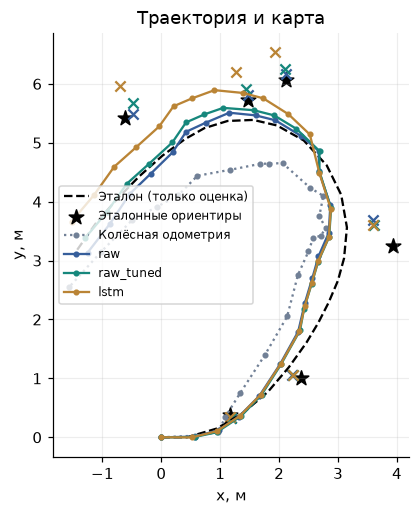

,ate_m,map_m
method,,
lstm,0.3098,0.2991
raw,0.7782,0.7598


Последняя таблица: пять фиксированных валидационных маршрутов, не итоговый тест.


In [15]:
from fusionlab import fusion_adapter as fa
# Зафиксированный выбор до окончательного теста F12.
MODEL_NAME='lstm' # @param ["lstm"]
RAW_SIGMA=.15
TUNED_SIGMA=.6  # выбран на отдельной валидации исторического пилота из {.065,.15,.30,.60}
ZERO=np.zeros(T)

def episode_compare(ref, X, specs, verbose=False):
    raw=fa.observations(ref); rows=[]; sols={}
    for label,p,a,sigma in specs:
        sol=fa.estimate_slam(raw,p,a=a,sigma=sigma)
        met=fa.evaluate(sol,ref)  # эталон только здесь, ПОСЛЕ solve
        rows.append(dict(method=label,ate_m=met['ate_rmse_m'],map_m=met['landmark_rmse_m'],
                         status=sol['status'],steps=sol['steps']))
        sols[label]=sol
    return pd.DataFrame(rows),sols

p_demo=predict(MODEL_NAME,X_demo)
res10,sols10=episode_compare(ref_demo,X_demo,[('raw',ZERO,0.,RAW_SIGMA),('raw_tuned',ZERO,0.,TUNED_SIGMA),(MODEL_NAME,p_demo,1.,RAW_SIGMA)])
display(res10.round(4));plot_estimate(ref_demo,wheel_path,sols10)
# Один маршрут не определяет средний эффект. Возьмём первые пять валидационных маршрутов.
val_rows=[]
for seed in VAL[:5]:
    X,_,ref=sy.generate(seed)
    tab,_=episode_compare(ref,X,[('raw',ZERO,0.,RAW_SIGMA),(MODEL_NAME,predict(MODEL_NAME,X),1.,RAW_SIGMA)])
    tab['seed']=seed; val_rows.append(tab)
display(pd.concat(val_rows).groupby('method')[['ate_m','map_m']].mean().round(4))
print('Последняя таблица: пять фиксированных валидационных маршрутов, не итоговый тест.')

### Два измерения одной координаты

При одинаковом весе двух измерений оценка координаты равна их среднему. Ошибки +1 и −1 м взаимно компенсируются. Если после поправки обе ошибки равны +0,5 м, их RMSE снижается с 1 до 0,5 м, а координата смещается на 0,5 м.

Для полноранговой матрицы $B$ в линейной модели $d=Bx^*+e$ ошибка решения равна $B^\dagger e$. Поэтому $\|\widehat x-x^*\|\leq \|e\|/\sigma_{\min}(B)$. Результат зависит от направления ошибки и геометрии измерений. Для сравнения нелинейных траекторий ниже считаю ATE отдельно.

In [16]:
for e in [np.array([1.,-1.]),np.array([.5,.5])]:
    print('RMSE измерений:',np.sqrt(np.mean(e**2)),'м | ошибка оценки:',abs(e.mean()),'м')
# В линейном графе F4: внесём произвольную ошибку только для проверки оценки.
xstar=np.array([1.,2.,3.]); error=np.array([.2,-.05,.07,-.12]); estimate=np.linalg.lstsq(B,B@xstar+error,rcond=None)[0]
smin=np.linalg.svd(B,compute_uv=False)[-1]
assert np.linalg.norm(estimate-xstar)<=np.linalg.norm(error)/smin+1e-12
print('Линейный граф: фактическая ошибка / верхняя оценка, м:',np.linalg.norm(estimate-xstar),np.linalg.norm(error)/smin)

RMSE измерений: 1.0 м | ошибка оценки: 0.0 м
RMSE измерений: 0.5 м | ошибка оценки: 0.5 м
Линейный граф: фактическая ошибка / верхняя оценка, м: 0.012186057606963285 0.032480640245741564


### Результат F10

На маршруте 23 полная поправка подняла ATE с 0,280 до 0,432 м. По пяти маршрутам валидации средняя ATE, наоборот, снизилась с 0,778 до 0,310 м. Поэтому доверие к прогнозу я подбираю на отдельных данных.

## F11. Доверие к поправке

Коэффициент доверия подбираю по разности показаний колёс и камеры на одном интервале.

Для каждой пары синхронных отсчётов $d_i$ — продольное приращение колёс минус приращение визуальной одометрии. $p_i$ — прогноз ошибки колёс. Обе величины в метрах, в осях корпуса. Критерий на калибровке
$$J(a)=\sum_i(d_i-a p_i)^2,\quad 0\le a\le1.$$
Производная равна $2a\sum_i p_i^2-2\sum_i p_i d_i$. Если $\sum_i p_i^2>0$, минимум на прямой равен отношению этих сумм. Ограничиваю его отрезком $[0,1]$. При пустой выборке или нулевых прогнозах выбираю $a=0$. Поскольку ноль допустим, $J(a^*)\le J(0)$ на этих же парах. На следующем маршруте возможен другой результат.

In [17]:
# Три случая, которые можно вычислить вручную.
for label,p,y in [('частичное доверие',[1.,2.],[.5,1.]),('противоположный знак',[1.,2.],[-1.,-2.]),('нет предложения',[0.,0.],[.5,1.])]:
    out=fa.calibrate_scale(p,y)
    print(label,':',out)
    assert out['after']<=out['before']+1e-12
assert fa.calibrate_scale([],[])['a']==0

частичное доверие : {'a': 0.5, 'n_pairs': 2, 'before': 0.625, 'after': 0.0, 'status': 'calibrated'}
противоположный знак : {'a': 0.0, 'n_pairs': 2, 'before': 2.5, 'after': 2.5, 'status': 'calibrated'}
нет предложения : {'a': 0.0, 'n_pairs': 2, 'before': 0.625, 'after': 0.625, 'status': 'zero_prediction'}


### Калибровочные маршруты

Использую восемь маршрутов 4000–4007 отдельно для штатного режима, отсутствия смещения и смены знака. В каждой паре колёса и камера наблюдают одно и то же начало и окончание интервала. Истинная траектория в расчёте коэффициента не участвует.

In [18]:
REGIMES=['nominal','null','shift']
cal_records={}; gates={}; cal_rows=[]
for reg in REGIMES:
    for name in [MODEL_NAME,'boost']:
        pp,yy=[],[]
        for seed in CAL:
            X,_,reference=sy.generate(seed,reg)
            raw=fa.observations(reference); ix,difference=fa.paired_diff(raw)
            pp.extend(predict(name,X)[ix]); yy.extend(difference)
        p,y=np.asarray(pp),np.asarray(yy)
        gate=fa.calibrate_scale(p,y)
        assert gate['status']=='calibrated' and gate['after']<=gate['before']+1e-12
        cal_records[reg,name]=(p,y); gates[reg,name]=gate['a']
        cal_rows.append(dict(regime=reg,method=name,**gate))
cal_table=pd.DataFrame(cal_rows)
display(cal_table.round(5))

,regime,method,a,n_pairs,before,after,status
0,nominal,lstm,1.00000,85,0.07529,0.01311,calibrated
1,nominal,boost,1.00000,85,0.07529,0.01213,calibrated
2,null,lstm,0.04715,85,0.00781,0.00770,calibrated
3,null,boost,0.04216,85,0.00781,0.00771,calibrated
4,shift,lstm,0.00000,85,0.06398,0.06398,calibrated
5,shift,boost,0.00000,85,0.06398,0.06398,calibrated


Ползунок меняет доверие $a$ при фиксированном наборе калибровочных пар. Минимум кривой даёт коэффициент для выбранного режима.

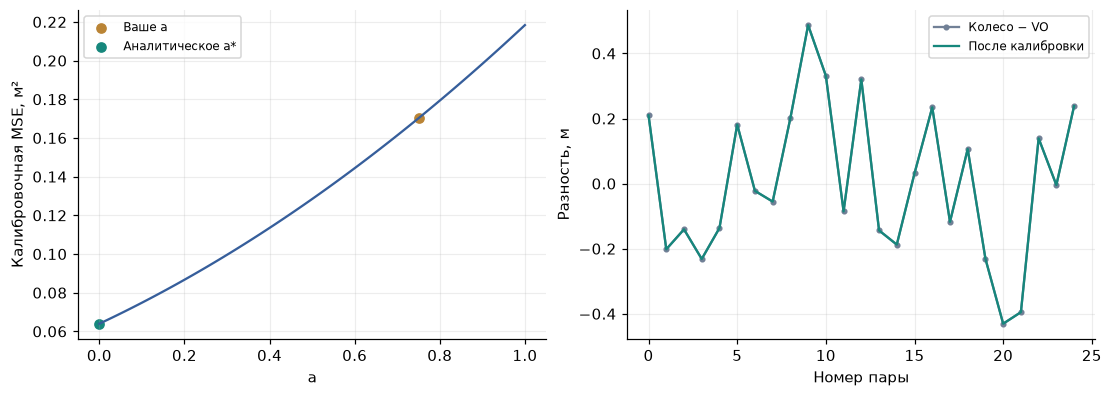

a*: 0.0 | ваша MSE: 0.17021241620562122 | минимум: 0.0639768072115091


In [19]:
# @title F11 · Ручка доверия
regime_f11='shift' # @param ["nominal", "null", "shift"]
a_manual=.75 # @param {type:"slider", min:0, max:1, step:0.05}
p,y=cal_records[regime_f11,MODEL_NAME]; a_star=gates[regime_f11,MODEL_NAME]
grid=np.linspace(0,1,101); curve=np.array([np.mean((y-a*p)**2) for a in grid])
fig,ax=plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
ax[0].plot(grid,curve,color=BLUE);ax[0].scatter([a_manual],[np.mean((y-a_manual*p)**2)],color=GOLD,label='Ваше a');ax[0].scatter([a_star],[np.mean((y-a_star*p)**2)],color=TEAL,label='Аналитическое a*');ax[0].set(xlabel='a',ylabel='Калибровочная MSE, м²');ax[0].legend(fontsize=8)
ax[1].plot(y[:25],'o-',ms=3,color=GRAY,label='Колесо − VO');ax[1].plot((y-a_star*p)[:25],color=TEAL,label='После калибровки');ax[1].set(xlabel='Номер пары',ylabel='Разность, м');ax[1].legend(fontsize=8);plt.show()
print('a*:',a_star,'| ваша MSE:',np.mean((y-a_manual*p)**2),'| минимум:',np.mean((y-a_star*p)**2))

### Проверка адаптера

Сравниваю исходный граф с результатом при нулевом доверии и при вызове без калибровки. Вес колёс в обоих вариантах одинаков.

In [20]:
raw=fa.observations(ref_demo); originals=[f.z.copy() for f in raw.factors]
changed=fa.correct_factors(raw,p_demo,a=1.,sigma=RAW_SIGMA)
unchanged=fa.correct_factors(raw,p_demo,a=0.,sigma=RAW_SIGMA)
for f,u,v,old in zip(raw.factors,unchanged.factors,changed.factors,originals):
    np.testing.assert_array_equal(f.z,old); np.testing.assert_array_equal(u.z,old)
    if f.kind!='wheel': np.testing.assert_array_equal(v.z,old)
sol_a0=fa.estimate_slam(raw,p_demo,a=0.,sigma=RAW_SIGMA)
sol_raw=fa.estimate_slam(raw,ZERO,a=0.,sigma=RAW_SIGMA)
sol_default=fa.estimate_slam(raw,p_demo,sigma=RAW_SIGMA)
np.testing.assert_array_equal(sol_default['x'],sol_raw['x'])
np.testing.assert_allclose(sol_a0['x'],sol_raw['x'],atol=1e-12)
try:
    fa.estimate_slam(ref_demo,p_demo)
except ValueError as exc: print('Защита от эталонных данных:',exc)
else: raise AssertionError('Нельзя передавать эталон решателю')
print('PASS: a=0, неизменность измерений, запрет эталона')

Защита от эталонных данных: remove reference fields before inference
PASS: a=0, неизменность измерений, запрет эталона


### Результат F11

Для LSTM получились коэффициенты 1,000 при штатном проскальзывании, 0,047 без систематической ошибки и 0,000 при смене знака. В последнем случае отрицательная поправка вышла бы за выбранный диапазон доверия. При нуле адаптер сохраняет исходные колёсные измерения.

## F12. Проверка на новых маршрутах

Проверяю, какой результат дают полная поправка, калиброванная и два варианта исходного SLAM. Во всех сравнениях сохраняю одинаковое начальное приближение.

До запуска ожидал, что в штатном режиме сеть уменьшит дрейф, а при смене знака полное доверие ухудшит результат. Для каждого режима беру маршруты 5000–5004. У исходного SLAM и вариантов с поправкой σ колёс равна 0,15 м. У отдельного варианта raw tuned σ = 0,60 м по валидации.

In [21]:
rows=[]; examples={}; started=time.perf_counter()
for reg in REGIMES:
    for seed in TEST:
        X,_,ref=sy.generate(seed,reg)
        p=predict(MODEL_NAME,X); q=predict('boost',X)
        specs=[('raw',ZERO,0.,RAW_SIGMA),('raw_tuned',ZERO,0.,TUNED_SIGMA),
               ('net_full',p,1.,RAW_SIGMA),('net_gate',p,gates[reg,MODEL_NAME],RAW_SIGMA),
               ('boost_full',q,1.,RAW_SIGMA),('boost_gate',q,gates[reg,'boost'],RAW_SIGMA)]
        table,sols=episode_compare(ref,X,specs)
        table['seed']=seed;table['regime']=reg;rows.append(table)
        if seed==TEST[0]: examples[reg]=(ref,sols)
    print('Завершён режим:',reg,flush=True)
results=pd.concat(rows,ignore_index=True)
assert len(results)==len(REGIMES)*len(TEST)*6 and np.isfinite(results[['ate_m','map_m']]).all().all()
summary=results.groupby(['regime','method'])[['ate_m','map_m','steps']].mean()
display(summary.round(4)); print('Время серии, с:',round(time.perf_counter()-started,1))
print('Статусы (все испытания):');display(pd.crosstab(results.method,results.status))

Завершён режим: nominal


Завершён режим: null


Завершён режим: shift


ate_m   map_m  steps
regime  method                           
nominal boost_full  0.4065  0.3996   10.6
        boost_gate  0.4065  0.3996   10.6
        net_full    0.4010  0.3939   10.8
        net_gate    0.4010  0.3939   10.8
        raw         0.5970  0.5538   11.0
        raw_tuned   0.5056  0.4777   11.4
null    boost_full  0.4473  0.4436   10.0
        boost_gate  0.3946  0.3867   10.2
        net_full    0.4636  0.4588    9.8
        net_gate    0.3940  0.3862   10.2
        raw         0.3981  0.3889   10.2
        raw_tuned   0.3996  0.3933   10.6
shift   boost_full  0.7588  0.7471   16.6
        boost_gate  0.4623  0.4574   10.4
        net_full    0.7886  0.7752   16.4
        net_gate    0.4623  0.4574   10.4
        raw         0.4623  0.4574   10.4
        raw_tuned   0.3967  0.3997   11.2

Время серии, с: 4.6
Статусы (все испытания):


status,gradient_small,max_iter,step_small
method,,,
boost_full,11,2,2
boost_gate,12,0,3
net_full,13,1,1
net_gate,13,0,2
raw,13,0,2
raw_tuned,15,0,0


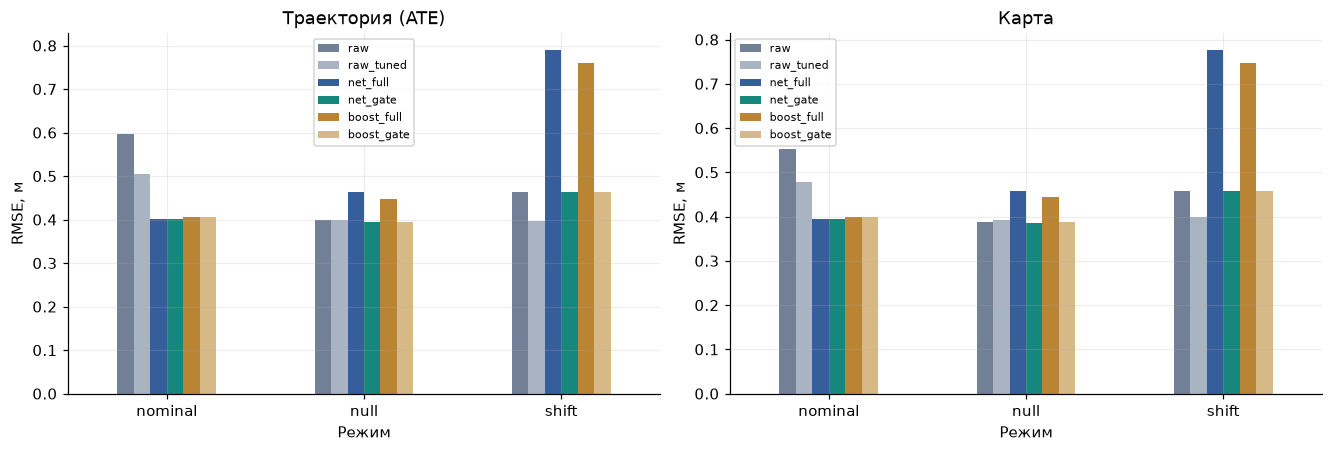

nominal | ΔATE net_gate − raw_tuned, среднее, м: -0.1045 | выигрышей: 4 из 5
null | ΔATE net_gate − raw_tuned, среднее, м: -0.0056 | выигрышей: 3 из 5
shift | ΔATE net_gate − raw_tuned, среднее, м: 0.0656 | выигрышей: 1 из 5


In [22]:
order=['raw','raw_tuned','net_full','net_gate','boost_full','boost_gate']
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,metric in zip(axes,['ate_m','map_m']):
    a=summary[metric].unstack('method').reindex(index=REGIMES,columns=order)
    a.plot.bar(ax=ax,color=[GRAY,'#a9b4c3',BLUE,TEAL,GOLD,'#d7b987'],rot=0)
    ax.set(xlabel='Режим',ylabel='RMSE, м',title='Траектория (ATE)' if metric=='ate_m' else 'Карта');ax.legend(fontsize=7)
plt.show()
# Парное сравнение по тем же маршрутам, без исключения неудобных результатов.
pair=results.pivot(index=['regime','seed'],columns='method',values='ate_m')
for reg in REGIMES:
    delta=pair.loc[reg,'net_gate']-pair.loc[reg,'raw_tuned']
    print(reg,'| ΔATE net_gate − raw_tuned, среднее, м:',round(delta.mean(),4),'| выигрышей:',int((delta<0).sum()),'из',len(delta))

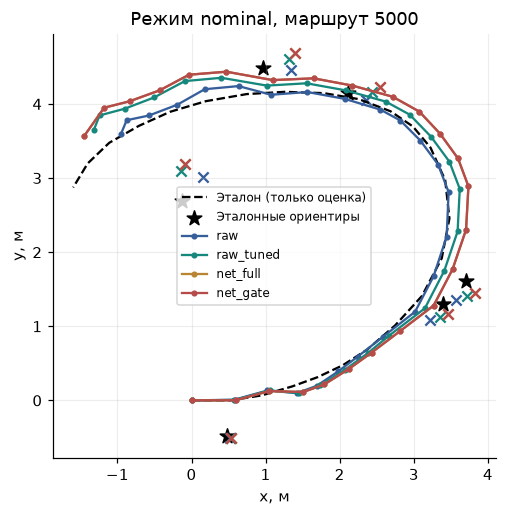

a*: 1.0


In [23]:
# @title F12 · Карта выбранного режима
regime_f12='nominal' # @param ["nominal", "null", "shift"]
ref12,all_sols=examples[regime_f12]
plot_estimate(ref12,None,{k:all_sols[k] for k in ['raw','raw_tuned','net_full','net_gate']},title=f'Режим {regime_f12}, маршрут {TEST[0]}')
print('a*:',gates[regime_f12,MODEL_NAME])

### Проверка решения
В таблице ниже значения ATE усреднены по пяти независимым маршрутам каждого режима. Знак разности показывает, как изменилась ошибка по отношению к подобранному классическому весу. Файл отчёта содержит решение по каждому режиму.

In [24]:
display(summary['ate_m'].unstack('method').round(4))
assert all(set(TEST).isdisjoint(x) for x in [TRAIN,VAL,CAL])
for reg in REGIMES:
    if gates[reg,MODEL_NAME] == 0:
        np.testing.assert_allclose(pair.loc[reg,'net_gate'],pair.loc[reg,'raw'],atol=1e-12)
print('Проверено совпадение с raw при нулевом доверии.')

method,boost_full,boost_gate,net_full,net_gate,raw,raw_tuned
regime,,,,,,
nominal,0.4065,0.4065,0.4010,0.4010,0.5970,0.5056
null,0.4473,0.3946,0.4636,0.3940,0.3981,0.3996
shift,0.7588,0.4623,0.7886,0.4623,0.4623,0.3967


Проверено совпадение с raw при нулевом доверии.


In [25]:
# @title Экспорт библиотеки и весов
import joblib, platform, sklearn
release=Path('fusionlab_release'); release.mkdir(exist_ok=True)
package=release/'fusionlab';package.mkdir(exist_ok=True)
for path in Path('fusionlab').glob('*.py'): shutil.copy2(path,package/path.name)
predictors[MODEL_NAME].save(release/'predictor.keras')
joblib.dump(predictors['boost'],release/'boost.joblib')
results.to_csv(release/'test_metrics.csv',index=False);cal_table.to_csv(release/'calibration.csv',index=False)
val_all.to_csv(release/'validation.csv')
config=dict(model=MODEL_NAME,window=W,channels=['load','vibration'],prediction_units='m per interval',
            train=TRAIN,validation=VAL,calibration=CAL,test=TEST,sigma_raw=RAW_SIGMA,sigma_tuned=TUNED_SIGMA,
            a_by_bench_scenario={r:gates[r,MODEL_NAME] for r in REGIMES},
            backend=keras.backend.backend(),keras=keras.__version__,numpy=np.__version__,sklearn=sklearn.__version__,python=platform.python_version())
(release/'config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
(release/'requirements.txt').write_text(f'numpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nkeras=={keras.__version__}\njoblib\n# Backend: TensorFlow >=2.16 or PyTorch; install one compatible with your environment.\n',encoding='utf-8')
(release/'README.md').write_text('''# FusionLab · учебный инкремент\n\nПлоский синтетический SLAM, известные соответствия, синхронные метрические факторы.\n`geometry2d`, `linear_solver`, `slam_core` — геометрия и решатели; `synthetic` — стенд; `learned_sensor` — предикторы; `fusion_adapter` — калибровка и исправление входов.\nВ рабочем backend Keras запустите из этой папки `python smoke_test.py`. `config.json` хранит версии, разбиение и коэффициенты отдельных сценариев. Коэффициент не переносится автоматически в неизвестный режим.\nИстина нужна только для обучения/оценки. Синтетические испытания не подтверждают физическую надёжность или универсальный выигрыш.\nСводные таблицы содержат свежий прогон пяти тестовых маршрутов в каждом из трёх режимов.\n''',encoding='utf-8')
res10.to_csv(release/'f10_demo.csv',index=False)
pd.concat(val_rows).to_csv(release/'f10_validation.csv',index=False)
summary.to_csv(release/'test_summary.csv')
(release/'requirements.txt').write_text('numpy==2.2.6\nscikit-learn==1.7.2\nkeras==3.11.3\ntensorflow-cpu==2.20.0\njoblib\nthreadpoolctl\n')
config['a_boost_by_bench_scenario']={r:gates[r,'boost'] for r in REGIMES}
(release/'config.json').write_text(json.dumps(config,indent=2))

2138

In [26]:
(release/'smoke_test.py').write_text('"""Run from the exported folder: python smoke_test.py."""\nimport os, importlib.util, json\nfrom pathlib import Path\nos.environ.setdefault(\'KERAS_BACKEND\', \'tensorflow\' if importlib.util.find_spec(\'tensorflow\') else \'torch\')\nos.environ.setdefault(\'OPENBLAS_NUM_THREADS\',\'1\')\nos.environ.setdefault(\'OMP_NUM_THREADS\',\'1\')\nimport numpy as np\nimport keras\nimport joblib\nfrom fusionlab import slam_core as sc, synthetic as sy, fusion_adapter as fa, learned_sensor as ls\nfrom fusionlab.geometry2d import pose_matrix, inverse\nfrom fusionlab.linear_solver import normal_system, fixed_point\nroot=Path(__file__).resolve().parent\nconfig=json.loads((root/\'config.json\').read_text())\nnet=keras.models.load_model(root/\'predictor.keras\',compile=False)\nboost=joblib.load(root/\'boost.joblib\')\nG=pose_matrix([1.,2.,.3]); np.testing.assert_allclose(inverse(G)@G,np.eye(3),atol=1e-12)\nA=np.array([[1.,0.],[-1.,1.],[0.,1.]]);z=np.array([1.,1.,2.1]);H,b,B,d=normal_system(A,z,np.ones(3))\nnp.testing.assert_allclose(fixed_point(H,b)[\'x\'],np.linalg.lstsq(B,d,rcond=None)[0],atol=1e-7)\nassert fa.calibrate_scale([1.,2.],[-1.,-2.])[\'a\']==0\nassert fa.calibrate_scale([],[])[\'a\']==0\nfor reg in [\'nominal\',\'shift\']:\n    X,_,ref=sy.generate(6000,reg); raw=fa.observations(ref)\n    pred=ls.predict_bias(net,X); assert pred.shape==(sy.T,)\n    assert ls.predict_bias(boost,X).shape==(sy.T,)\n    a=config[\'a_by_bench_scenario\'][reg]  # bench scenario only\n    sol=fa.estimate_slam(raw,pred,a=a,sigma=config[\'sigma_raw\'])\n    baseline=fa.estimate_slam(raw,np.zeros(sy.T),a=0,sigma=config[\'sigma_raw\'])\n    if reg == \'shift\':\n        by_default = fa.correct_factors(raw, pred)\n        for original, revised in zip(raw.factors, by_default.factors, strict=True):\n            np.testing.assert_array_equal(revised.z, original.z)\n        uncalibrated = fa.estimate_slam(raw, pred, sigma=config[\'sigma_raw\'])\n        np.testing.assert_array_equal(uncalibrated[\'x\'], baseline[\'x\'])\n    if a==0: np.testing.assert_allclose(sol[\'x\'],baseline[\'x\'],atol=1e-12)\n    print(reg, \'ATE [m]\', round(fa.evaluate(sol,ref)[\'ate_rmse_m\'],4), \'status\',sol[\'status\'])\nprint(\'PASS: export loaded, geometry, linear solver, gate, new episode\')\n', encoding='utf-8')
import subprocess
completed=subprocess.run([sys.executable,'smoke_test.py'],cwd=release,capture_output=True,text=True,timeout=180)
print(completed.stdout)
if completed.returncode != 0:
    print(completed.stderr)
    raise RuntimeError('Проверка экспортированного пакета не пройдена')
shutil.rmtree(package/'__pycache__',ignore_errors=True)
archive=shutil.make_archive('fusionlab_student_increment','zip',root_dir=release)
print('Готовый архив:', Path(archive).name)

nominal ATE [m] 0.4067 status gradient_small
shift ATE [m] 0.6717 status step_small
PASS: export loaded, geometry, linear solver, gate, new episode

Готовый архив: fusionlab_student_increment.zip


## Итог F10–F12

**1. Схема.** Окно нагрузки и вибрации (8 отсчётов × 2 канала) → LSTM → прогноз ошибки $p$ в метрах. Синхронные пары «колёса и VO» → коэффициент $a$. Исходное приращение колёс $z_x$ → поправка $z_x-a p$ → граф SE(2). В тот же граф поступают VO, гироскоп, дальности и пеленги. LM оценивает позы, ориентиры и смещение гироскопа. Эталон симулятора нужен только для оценки результата.

**2. Формула доверия.** $d_i$ — разность продольных приращений колёс и VO в осях корпуса, $p_i$ — прогноз на том же интервале, оба в метрах. Для $J(a)=\sum_i(d_i-a p_i)^2$ при $\sum_i p_i^2>0$ из $J'(a)=0$ получаю $a_0=\sum_i p_i d_i/\sum_i p_i^2$. Минимум выпуклой функции на $[0,1]$ — ближайшее к $a_0$ число из этого отрезка. Отсюда $J(a^*)\le J(0)$ на калибровочных парах. Если пригодных пар нет, беру ноль.

**3. Опыт.** Выбрал LSTM по валидации F9 и до испытаний ожидал выигрыш в штатном режиме и ухудшение при смене знака для полной поправки. Калибровка — маршруты 4000–4007. В таблице средняя ATE на пяти других маршрутах 5000–5004, в метрах. У трёх вариантов с исходным весом σ = 0,15 м.

| Режим | Исходный SLAM | LSTM, полная | LSTM, калиброванная | Исходный SLAM, σ = 0,60 м |
|---|---:|---:|---:|---:|
| Штатный | 0,597 | 0,401 | 0,401 | 0,506 |
| Без систематической ошибки | 0,398 | 0,464 | 0,394 | 0,400 |
| Смена знака | 0,462 | 0,789 | 0,462 | 0,397 |

**4. Граница.** Колёса и VO должны измерять один интервал в согласованных осях. Адаптер обнаруживает повтор измерения одного датчика на интервале и передачу эталонных полей в решатель. Общая систематическая ошибка камеры и колёс может пройти проверку. Закрепление первой позы задаёт систему координат. На реальном роботе ещё надо проверить часы и калибровку камеры. Теорема Банаха даёт сходимость итераций сжимающего отображения к его неподвижной точке в полном пространстве. Для нелинейного графа такой гарантии в этом опыте нет.

**5. Код и решение.** В модуле `fusionlab/wheel_channel.py` функция `correct_graph` переносит поправку в граф КТ3. Для стенда F9 служит `fusion_adapter.estimate_slam`. Из распакованного архива запускаю `python smoke_test.py` с моделью и весами рядом. На штатном покрытии оставляю калиброванную LSTM, которая дала 0,401 м против 0,506 м у исходного SLAM с подобранным весом. После смены знака и при отсутствии пригодной калибровки поправку выключаю.